# 04 — Compare the initial-condition methods

Reads the outputs saved by the three workflows (`DIAG_ROOT/<method>/data/`, `util/ic_store.py`) and compares
their initial conditions for land and sea ice.

| Notebook | Workflow | Method (`OUT_ROOT/YYYYMMDD/<comp>/<method>/`) |
| --- | --- | --- |
| `01_clim_match_ic.ipynb` | climatology-match | `clim` |
| `02_obs_match_ic.ipynb` | observation-match | `obs` (observations chosen by `OBS_SET`) |
| `03_hybrid_ic.ipynb` | climatology + observed anomaly | `hybrid_ic` |
| `04_compare_ic_methods.ipynb` | comparison of the methods | reads the outputs saved by 01-03 |

**What is compared with what**

- **Target: the observed anomaly** on the initialization date (ERA5-Land for land, NOAA/NSIDC CDR for sea-ice
  concentration), on every date with observations (section 3). This is what `obs` and `hybrid_ic` aim for.
  `clim` aims for the climatology instead (01), so its score here shows what is lost by ignoring the
  observations rather than what it optimizes.
- **Reference: the JRA55-FOSIRL 2015 IC** (2015 dates only). The land, river, and sea-ice states of the archive
  are JRA55-FOSIRL restarts, so on the 2015 dates this is the model state a perfect method would reproduce.
  It is scored against the observations next to the methods (section 3, leftmost), and the methods are
  compared with it in section 4.

All scores use standardized anomalies (each source from its own climatology-year mean and spread), on the
selection box (15x30) and at model points; only fields with an observed counterpart enter section 3. The
scores are comparable when the workflows ran with the same years, box, and observations (section 1).

Add your own diagnostics below: `ic_store.load_table(DIAG_ROOT, name, METHODS)` gives any saved table for all
methods (with a `method` column), `ic_store.load_states(DIAG_ROOT, method, date)` the initial-condition key
fields at model points, and `ic_store.observed_similarity` scores any states against the observations.

In [1]:
from pathlib import Path
import importlib
import sys
import warnings

import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("util").resolve()))     # run from this directory
import anom_restart
import box_loo
import clim_restart as cr
import ic_eval as ice
import ic_store

# Reload so edits to util/ take effect without restarting the kernel.
for module in (cr, box_loo, anom_restart, ice, ic_store):
    importlib.reload(module)

ice.ensure_proj_data()
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 80     # inline figures; saved figures use FIG_DPI
quiet = lambda *args: None

In [2]:
DIAG_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic")
CACHE_DIR = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/cache")
IC_SOURCE = "JRA55-FOSIRL"    # source of the archive restarts (the 2015 reference)
ice.IC_SOURCE = IC_SOURCE
REFERENCE = f"{IC_SOURCE} 2015"
METHODS   = ["clim", "obs", "hybrid_ic"]   # workflow order (method directories under DIAG_ROOT)
LABELS    = {REFERENCE: f"reference: {REFERENCE} IC", "clim": "climatology-match", "obs": "observation-match",
             "hybrid_ic": "hybrid (clim + observed anomaly)"}
COLORS    = {REFERENCE: "0.15", "clim": "0.6", "obs": "tab:blue", "hybrid_ic": "tab:red"}
SAVE_DIAG = True
FIG_DPI   = 150
DIAG = DIAG_ROOT / "compare"

## 1. Settings of each run

Check that the years, box, and observations agree before comparing scores. Section 3 rebuilds the plans
(candidate and climatology years, observations) from the settings of the first method.

In [3]:
import json

KEYS = ["SEARCH_FIRST_YEAR", "SEARCH_LAST_YEAR", "EXCLUDE_YEARS", "CLIM_FIRST_YEAR", "CLIM_LAST_YEAR",
        "EXCLUDE_TARGET_YEAR", "BOX", "BOX_SHIFTS", "MODE", "COMPONENT_WEIGHTS", "EVAL_OBS"]
configs = {m: json.loads((DIAG_ROOT / m / "data" / "config.json").read_text()) for m in METHODS}
ipd.display(pd.DataFrame({m: {k: str(c.get(k)) for k in KEYS} for m, c in configs.items()}))

cfg = configs[METHODS[0]]
BOX = tuple(cfg["BOX"]) if cfg["BOX"] else None
EVAL_OBS = cfg["EVAL_OBS"]
common = dict(src_root=cfg["SRC_ROOT"], out_root=cfg["OUT_ROOT"], src_prefix=cfg["SRC_PREFIX"],
              components=cfg["COMPONENTS"], first_year=cfg["SEARCH_FIRST_YEAR"], last_year=cfg["SEARCH_LAST_YEAR"],
              clim_first_year=cfg["CLIM_FIRST_YEAR"], clim_last_year=cfg["CLIM_LAST_YEAR"],
              exclude_years=cfg["EXCLUDE_YEARS"], exclude_target_year=cfg["EXCLUDE_TARGET_YEAR"],
              obs_root=EVAL_OBS["root"], obs_fields=EVAL_OBS["fields"])
DATES = [d for d in cfg["TARGET_DATES"]
         if cr.era5_available(d, obs_root=EVAL_OBS["root"], obs_fields=EVAL_OBS["fields"], components=cfg["COMPONENTS"])]
plans = {d: cr.make_plan(d, "obs", **common) for d in DATES}
print(f"dates with observations: {DATES}; box {BOX}")

,clim,obs,hybrid_ic
SEARCH_FIRST_YEAR,1995,1995,1995
SEARCH_LAST_YEAR,None,None,None
EXCLUDE_YEARS,[],[],[]
CLIM_FIRST_YEAR,None,None,None
CLIM_LAST_YEAR,None,None,None
EXCLUDE_TARGET_YEAR,True,True,True
BOX,"[15.0, 30.0]","[15.0, 30.0]","[15.0, 30.0]"
BOX_SHIFTS,4,4,4
MODE,joint,joint,joint
COMPONENT_WEIGHTS,"{'elm': 1.0, 'mpassi': 1.0}","{'elm': 1.0, 'mpassi': 1.0}","{'elm': 1.0, 'mpassi': 1.0}"


dates with observations: ['2015-02-01', '2015-05-01', '2015-08-01', '2015-11-01', '2026-02-01', '2026-05-01', '2026-08-01']; box (15.0, 30.0)


## 2. Years used

The selected year (`clim`, `obs`) or the base year of the adjusted state (`hybrid_ic`).

In [4]:
selection = ic_store.load_table(DIAG_ROOT, "selection", METHODS)
ipd.display(selection[selection["component"] == "elm"].pivot(index="target_date", columns="method", values="year")[METHODS])

method,clim,obs,hybrid_ic
target_date,,,
2015-02-01,2010.0,2014.0,2010.0
2015-05-01,2004.0,2014.0,2004.0
2015-08-01,2009.0,2017.0,2009.0
2015-11-01,2008.0,2014.0,2008.0
2026-02-01,2010.0,2010.0,2010.0
2026-05-01,2009.0,2011.0,2009.0
2026-08-01,2009.0,2016.0,2009.0
2026-11-01,1995.0,NaN,NaN


## 3. Target: the observed anomaly

Every method's initial condition, and on the 2015 dates the JRA55-FOSIRL 2015 IC (the reference, leftmost),
against the observed standardized anomaly on the initialization date (`ic_store.observed_similarity`, saved as
`observed_similarity.csv`): `r` is the area-weighted pattern correlation (higher is closer) and `d` the RMS
difference of the standardized anomalies (lower is closer; a typical archive year has a joint D of about 1.4-1.6).
Section 3.3 shows D, RMSE, and r for each variable and date in one figure.
`clim` targets the climatology, so its row shows the cost of ignoring the observations.

### 3.1 Joint distance from the observed anomaly

In [5]:
sim = []
for date, plan in plans.items():
    states = {**ic_store.reference_state(plan, CACHE_DIR),
              **{m: ic_store.load_states(DIAG_ROOT, m, date)[0] for m in METHODS
                 if (DIAG_ROOT / m / "data" / f"states_{date.replace('-', '')}.npz").is_file()}}
    sim.append(ic_store.observed_similarity(plan, states, box=BOX, cache_dir=CACHE_DIR))
sim = pd.concat(sim, ignore_index=True)
ice.save_table(sim, "observed_similarity", DIAG, SAVE_DIAG)
STATES = [s for s in [REFERENCE, *METHODS] if s in set(sim["state"])]

# Joint distance as in the common score: RMS over a component's fields, then over the components.
comp_d = sim.groupby(["scale", "target_date", "state", "component"])["d"].apply(lambda d: np.sqrt((d ** 2).mean()))
joint = comp_d.groupby(["scale", "target_date", "state"]).apply(lambda d: np.sqrt((d ** 2).mean()))
joint = joint.unstack("state")[STATES]
ipd.display(joint.round(3))

[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/compare/data/observed_similarity.csv


state               JRA55-FOSIRL 2015   clim    obs  hybrid_ic
scale  target_date                                            
15x30  2015-02-01               0.718  1.237  1.108      0.625
       2015-05-01               0.751  1.305  1.086      0.704
       2015-08-01               0.729  1.223  1.179      0.554
       2015-11-01               0.744  1.456  1.163      0.712
       2026-02-01                 NaN  1.292  1.292      0.703
       2026-05-01                 NaN  1.457  1.252      0.605
       2026-08-01                 NaN  1.502  1.328      0.592
points 2015-02-01               1.045  1.250  1.287      0.699
       2015-05-01               1.037  1.355  1.307      0.843
       2015-08-01               1.060  1.302  1.316      0.704
       2015-11-01               1.020  1.456  1.269      0.815
       2026-02-01                 NaN  1.361  1.361      0.828
       2026-05-01                 NaN  1.477  1.375      0.780
       2026-08-01                 NaN  1.482  1.466      0.791

### 3.2 Field by field: pattern correlation with the observed anomaly

Mean over the 2015 dates (where the reference exists) and over all dates with observations. The reference
shows how well the true model state of 2015 matches the observations; values above it are possible because the
observations, not the model state, are the target.

In [6]:
d2015 = [d for d in plans if d.startswith("2015")]
for scale in dict.fromkeys(sim["scale"]):
    s = sim[sim["scale"] == scale]
    t = s[s["target_date"].isin(d2015)].pivot_table(index=["component", "field"], columns="state", values="r")[STATES]
    t.columns = [f"{c} (2015)" for c in t.columns]
    t_all = s.pivot_table(index=["component", "field"], columns="state", values="r")[METHODS]
    t_all.columns = [f"{c} (all dates)" for c in t_all.columns]
    print(f"pattern correlation r with the observed anomaly ({scale})")
    ipd.display(pd.concat([t, t_all], axis=1).round(2))

pattern correlation r with the observed anomaly (15x30)


JRA55-FOSIRL 2015 (2015)  clim (2015)  obs (2015)  hybrid_ic (2015)  clim (all dates)  obs (all dates)  hybrid_ic (all dates)
component field                                                                                                                                                     
elm       snow water equivalent                            0.56        -0.01        0.39              0.51             -0.01             0.35                   0.49
          subsurface soil temperature                      0.74         0.03        0.35              0.79             -0.01             0.32                   0.73
          subsurface soil water                            0.59         0.01        0.12              0.93             -0.02             0.10                   0.93
          surface soil temperature                         0.86         0.00        0.09              0.94              0.02             0.15                   0.93
          surface soil water                               0.68         0.09        0.01              0.82              0.08             0.10                   0.80
mpassi    NH ice concentration                             0.77        -0.04        0.39              0.85              0.07             0.38                   0.87
          SH ice concentration                             0.85        -0.05        0.53              0.61              0.01             0.52                   0.70

pattern correlation r with the observed anomaly (points)


JRA55-FOSIRL 2015 (2015)  clim (2015)  obs (2015)  hybrid_ic (2015)  clim (all dates)  obs (all dates)  hybrid_ic (all dates)
component field                                                                                                                                                     
elm       snow water equivalent                            0.18        -0.01        0.10              0.25             -0.00             0.07                   0.23
          subsurface soil temperature                      0.58         0.05        0.20              0.79              0.01             0.18                   0.75
          subsurface soil water                            0.39         0.02        0.11              0.82              0.03             0.08                   0.81
          surface soil temperature                         0.71        -0.00        0.06              0.92              0.00             0.06                   0.92
          surface soil water                               0.38         0.04        0.04              0.69              0.02             0.04                   0.69
mpassi    NH ice concentration                             0.49        -0.05        0.17              0.70             -0.03             0.12                   0.70
          SH ice concentration                             0.56        -0.05        0.25              0.47              0.00             0.25                   0.58

### 3.3 By variable: D, RMSE, and anomaly pattern correlation against the observations

One figure per scale, one row per variable. On each date, the three initial conditions (and on the 2015 dates the
JRA55-FOSIRL 2015 reference) against the same observed anomaly: (1) the distance D of the variable (RMS
difference of the standardized anomalies, in standard deviations), (2) the same difference as an RMSE in model
units (D times the variable's interannual spread at that scale, i.e. the observed anomaly expressed in model
units), and (3) the anomaly pattern correlation.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/compare/figure/observed_scores_by_variable_15x30.png


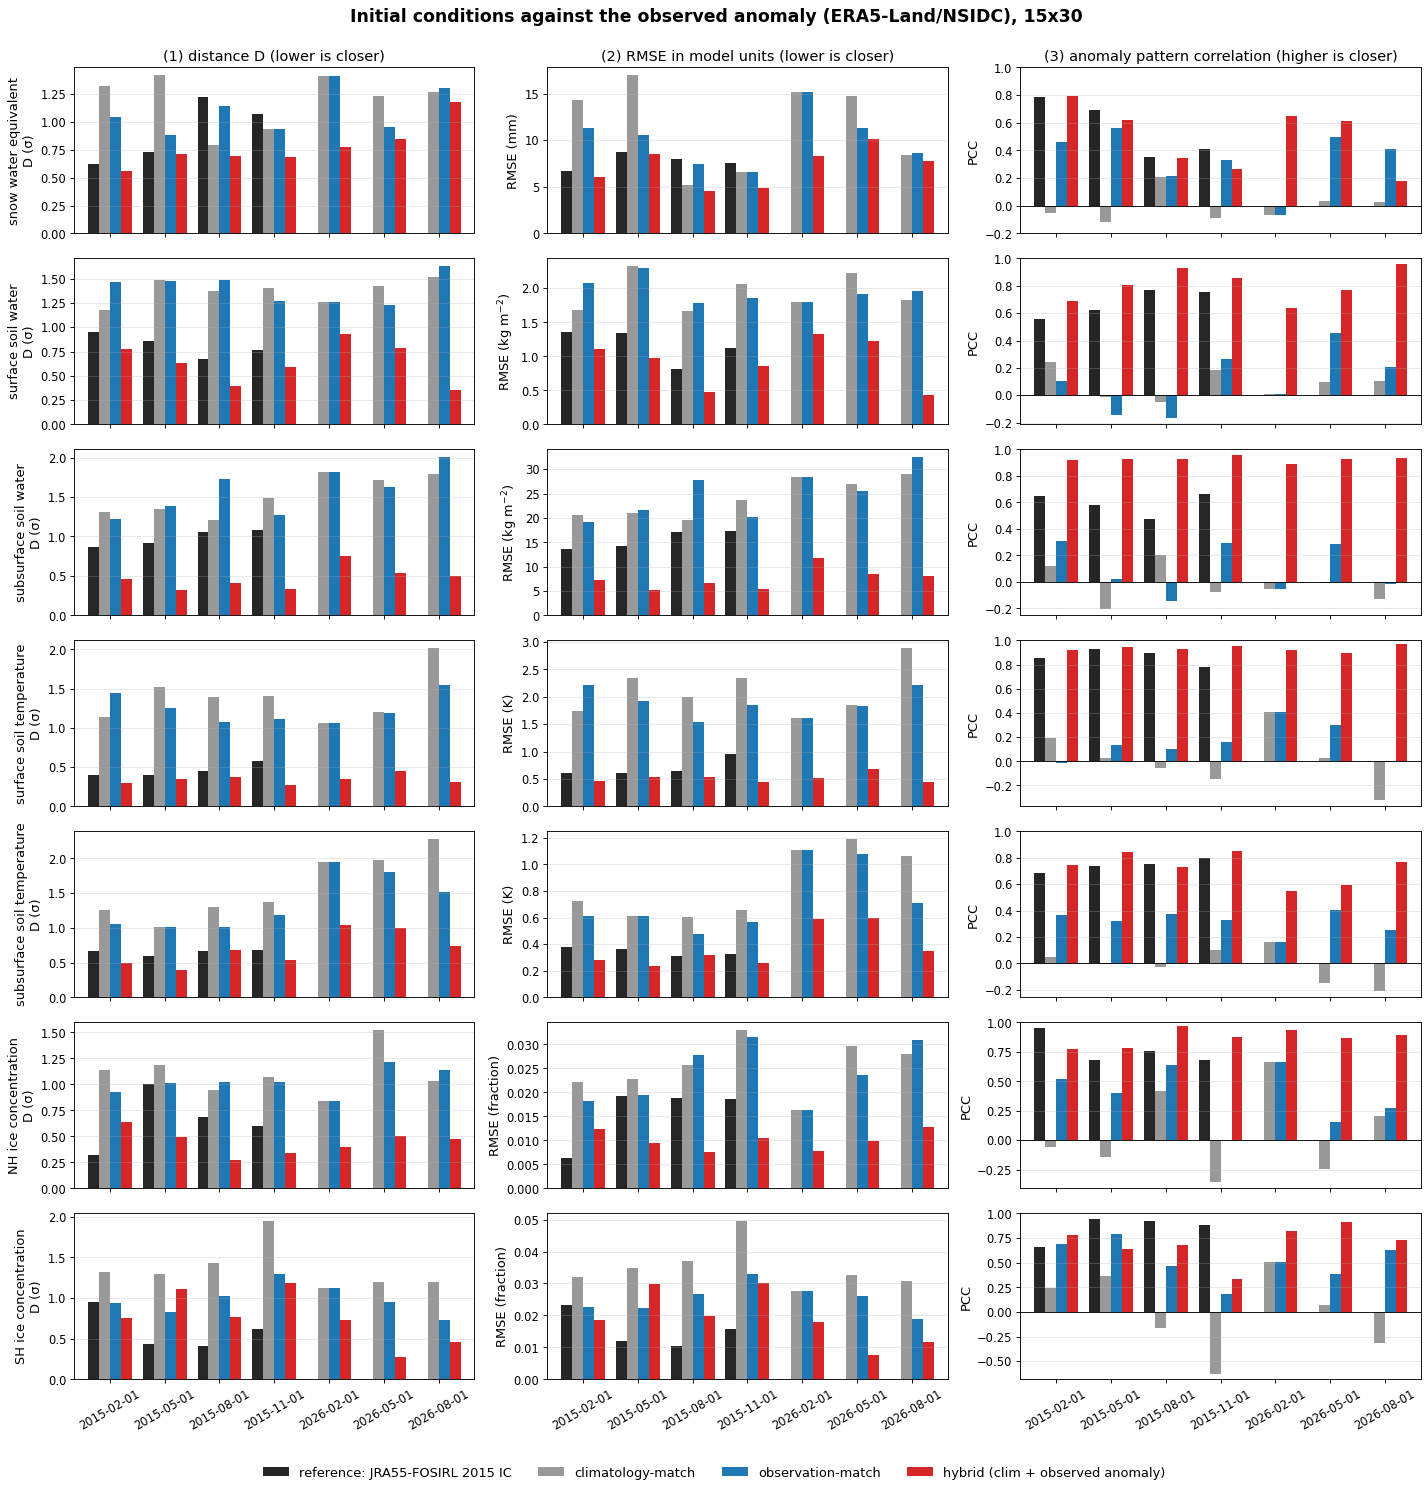

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/compare/figure/observed_scores_by_variable_points.png


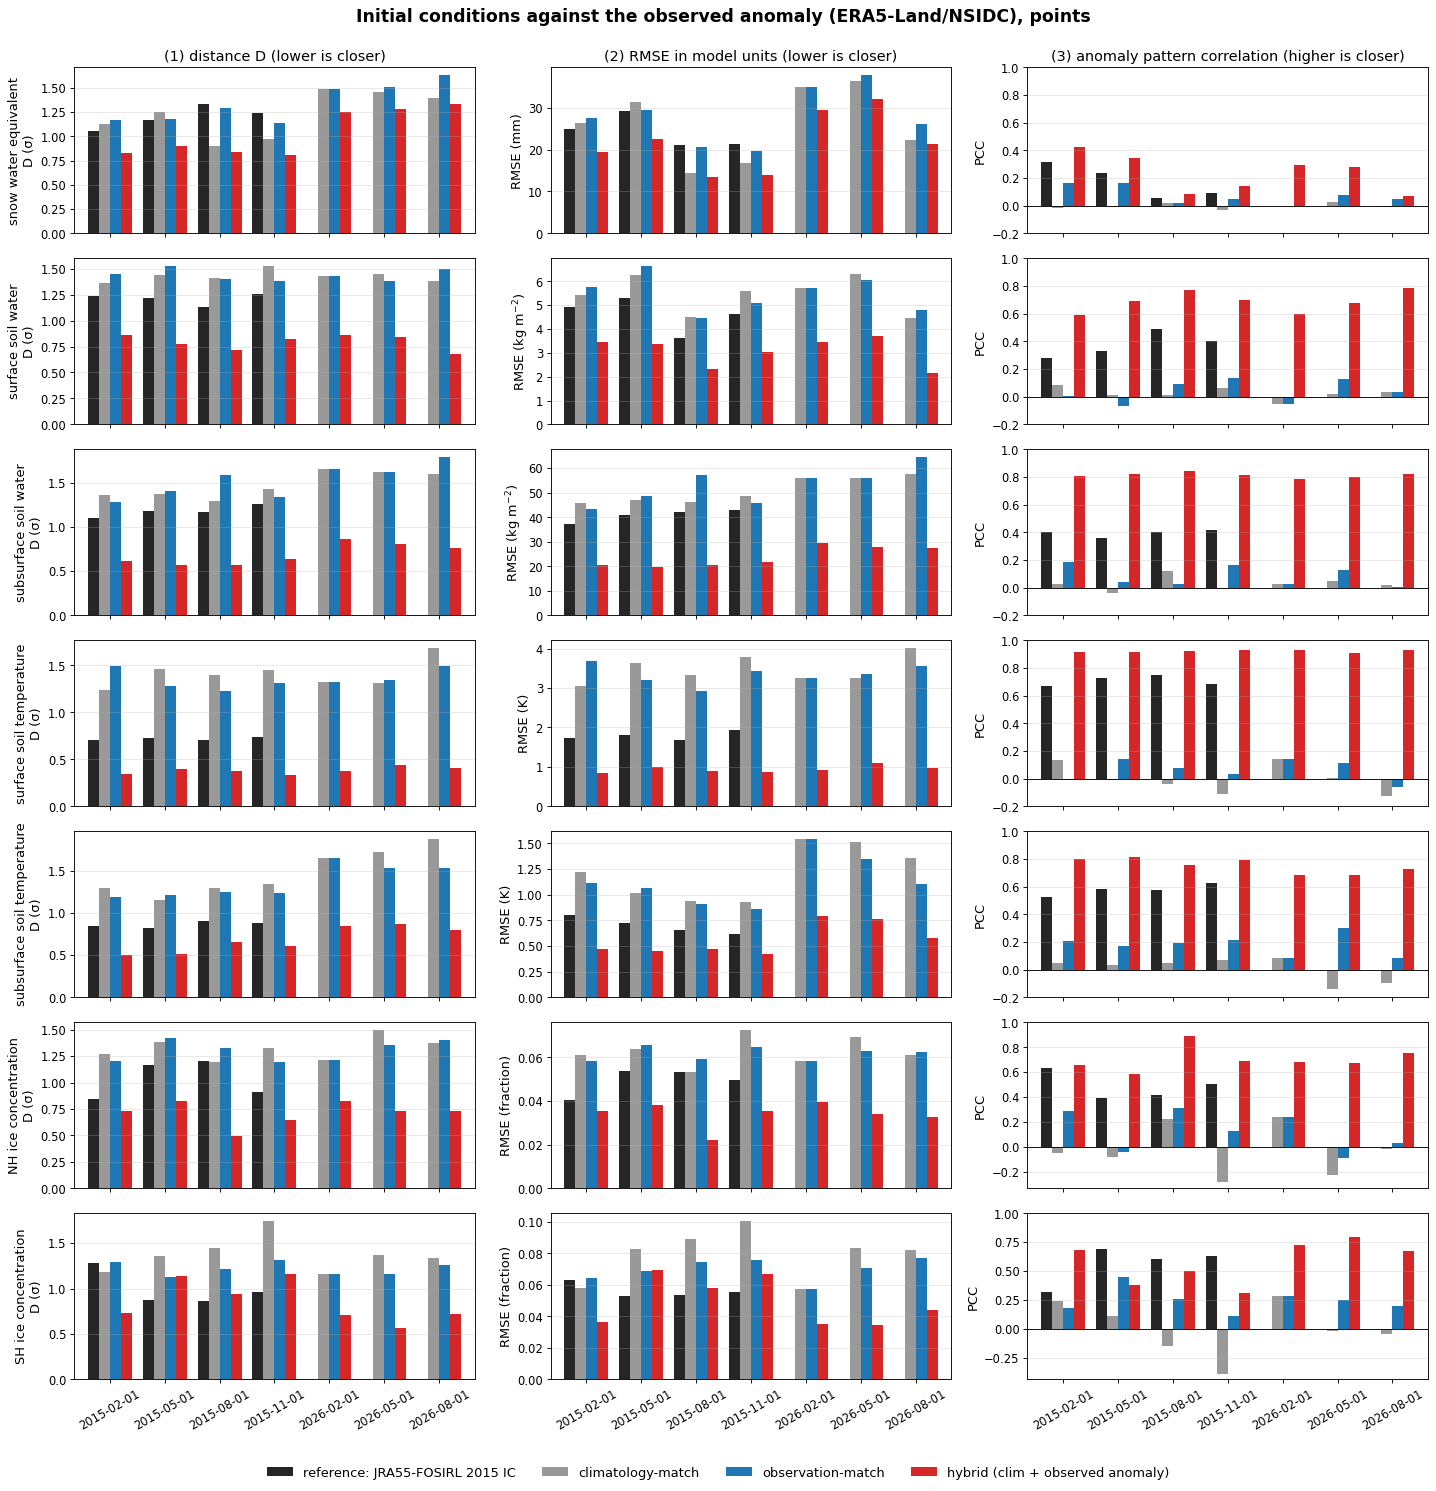

In [7]:
# ---- Figure setup ---------------------------------------------------------------------------
SCALES     = list(dict.fromkeys(sim["scale"]))   # one figure per scale: the selection box, model points
FONTSIZE   = 13
PANEL_SIZE = (6.0, 2.7)       # width, height of one panel (inches)
# ---------------------------------------------------------------------------------------------
fields = list(dict.fromkeys(zip(sim["component"], sim["field"])))
colors = [COLORS[c] for c in STATES]
metrics = [("d", "D (σ)", "(1) distance D (lower is closer)"),
           ("rmse", "RMSE", "(2) RMSE in model units (lower is closer)"),
           ("r", "PCC", "(3) anomaly pattern correlation (higher is closer)")]
for scale in SCALES:
    s = sim[sim["scale"] == scale]
    fig, axes = plt.subplots(len(fields), 3, figsize=(PANEL_SIZE[0] * 3, PANEL_SIZE[1] * len(fields)),
                             sharex=True, squeeze=False)
    for r, (comp, name) in enumerate(fields):
        sf = s[(s["component"] == comp) & (s["field"] == name)]
        units = ice.FIELD_UNITS.get(name, "")
        for c, (metric, ylabel, title) in enumerate(metrics):
            ax = axes[r, c]
            t = sf.pivot_table(index="target_date", columns="state", values=metric).reindex(columns=STATES)
            t.plot.bar(ax=ax, width=0.8, color=colors, legend=False, rot=30)
            if metric == "r":
                ax.axhline(0, color="k", lw=0.8)
                ax.set_ylim(min(-0.2, float(np.nanmin(t.values)) - 0.05), 1.0)
            label = f"{ylabel} ({units})" if metric == "rmse" else ylabel
            ax.set_ylabel(f"{name}\n{label}" if c == 0 else label, fontsize=0.9 * FONTSIZE)
            ax.set_xlabel("")
            ax.tick_params(labelsize=0.8 * FONTSIZE)
            ax.grid(alpha=0.3, axis="y")
            if r == 0:
                ax.set_title(title, fontsize=FONTSIZE)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, [LABELS.get(l, l) for l in labels], loc="lower center", ncol=len(labels),
               fontsize=0.9 * FONTSIZE, frameon=False)
    fig.suptitle(f"Initial conditions against the observed anomaly ({EVAL_OBS['label']}), {scale}",
                 fontsize=1.2 * FONTSIZE, fontweight="bold")
    fig.tight_layout(rect=(0, 0.03, 1, 0.98))
    ice.save_fig(fig, f"observed_scores_by_variable_{scale}", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

**Figure 3.3.** Scores of each initial condition against the observed anomaly (ERA5-Land for the land fields,
NOAA/NSIDC CDR for sea-ice concentration), one figure per scale: the selection box (`15x30`, area-weighted
means over 15°x30° boxes) and the model points (`points`). Rows: snow water equivalent, surface and subsurface
soil water, surface and subsurface soil temperature, and NH and SH sea-ice concentration. Columns: (1) the
distance D, the RMS difference between the standardized anomaly of the initial condition and the observed
standardized anomaly, in standard deviations (lower is closer); (2) the same difference as an RMSE in model
units, D times the interannual spread of the variable at that scale (lower is closer); (3) the area-weighted
pattern correlation of the two anomalies (higher is closer). Bars on each date: black, the JRA55-FOSIRL 2015 IC
(the true model state, 2015 dates only); grey, climatology-match (`clim`); blue, observation-match (`obs`);
red, hybrid (`hybrid_ic`). Dates without observations yet (2026-11-01) are left out. Anomalies are taken from the
1995-2018 climatology of each dataset, without the target year on the 2015 dates.

Notes for reading the figure: the hybrid initial condition is built from this observed anomaly, so its
scores are not independent of the observations; the black bars show how close the true model state comes
to the observations, a practical limit for the selection methods. Where climatology-match and observation-match
select the same year (2026-02-01, 2010), their bars are identical.

## 4. Reference: the JRA55-FOSIRL 2015 IC (2015 dates)

How close each method comes to the true model state on the 2015 dates.

### 4.1 Joint distance from the JRA55-FOSIRL 2015 IC

From the common score saved by each workflow (`state_distance.csv`; observable fields, lower is closer).

In [8]:
state = ic_store.load_table(DIAG_ROOT, "state_distance", METHODS)
state = state[(state["state"] == state["method"]) & state["versus"].str.startswith(IC_SOURCE)]
table = state.pivot_table(index=["scale", "target_date"], columns="method", values="joint")[METHODS]
ice.save_table(table.reset_index(), "reference_distance_by_method", DIAG, SAVE_DIAG)
ipd.display(table.round(3))

[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/compare/data/reference_distance_by_method.csv


method               clim    obs  hybrid_ic
scale  target_date                         
15x30  2015-02-01   1.381  1.163      0.959
       2015-05-01   1.465  0.961      1.006
       2015-08-01   1.168  1.135      0.803
       2015-11-01   1.547  1.210      0.975
points 2015-02-01   1.402  1.302      1.143
       2015-05-01   1.464  1.156      1.194
       2015-08-01   1.320  1.299      1.090
       2015-11-01   1.502  1.272      1.111

### 4.2 Field by field: similarity to the JRA55-FOSIRL 2015 IC

Mean over the 2015 dates of the pattern correlation (`r_box`, `r_grid`) and RMS difference (`d_box`, `d_grid`)
of standardized anomalies against the JRA55-FOSIRL 2015 IC, for every key field (including sea-ice thickness
and snow on ice); `observed` is the observed anomaly itself.

In [9]:
similarity = ic_store.load_table(DIAG_ROOT, "field_similarity", METHODS)
own = similarity[similarity["source"] == similarity["method"]]
obs_ref = similarity[~similarity["source"].isin(METHODS)].drop_duplicates(["target_date", "field", "source"])
for metric in ["r_box", "d_box", "r_grid", "d_grid"]:
    t = own.pivot_table(index=["component", "field"], columns="method", values=metric)[METHODS]
    t["observed"] = obs_ref.pivot_table(index=["component", "field"], values=metric).iloc[:, 0]
    print(metric)
    ipd.display(t.round(3))

r_box


method                                  clim    obs  hybrid_ic  observed
component field                                                         
elm       snow water equivalent        0.154  0.749      0.473     0.560
          subsurface soil temperature -0.005  0.435      0.701     0.744
          subsurface soil water        0.092  0.389      0.621     0.591
          surface soil temperature     0.025  0.137      0.815     0.863
          surface soil water           0.031  0.152      0.561     0.677
mpassi    NH ice concentration        -0.036  0.338      0.566     0.767
          NH ice thickness             0.073  0.531      0.202       NaN
          NH snow on ice               0.208  0.176      0.223       NaN
          SH ice concentration        -0.108  0.466      0.391     0.852
          SH ice thickness             0.197  0.219      0.294       NaN
          SH snow on ice              -0.146  0.198     -0.157       NaN

d_box


method                                  clim    obs  hybrid_ic  observed
component field                                                         
elm       snow water equivalent        1.318  0.777      1.001     0.912
          subsurface soil temperature  1.360  1.071      0.704     0.652
          subsurface soil water        1.330  1.204      0.910     0.981
          surface soil temperature     1.339  1.191      0.527     0.457
          surface soil water           1.415  1.325      0.921     0.814
mpassi    NH ice concentration         1.192  1.055      0.837     0.654
          NH ice thickness             0.855  0.879      0.770       NaN
          NH snow on ice               1.073  1.061      1.050       NaN
          SH ice concentration         1.538  1.095      1.128     0.602
          SH ice thickness             1.365  1.506      1.246       NaN
          SH snow on ice               1.915  1.844      1.866       NaN

r_grid


method                                  clim    obs  hybrid_ic  observed
component field                                                         
elm       snow water equivalent        0.033  0.727      0.284     0.175
          subsurface soil temperature  0.044  0.337      0.549     0.578
          subsurface soil water        0.004  0.371      0.386     0.394
          surface soil temperature    -0.011  0.081      0.643     0.707
          surface soil water           0.010  0.212      0.327     0.377
mpassi    NH ice concentration        -0.016  0.109      0.267     0.486
          NH ice thickness             0.060  0.176      0.106       NaN
          NH snow on ice               0.155  0.119      0.181       NaN
          SH ice concentration        -0.099  0.240      0.177     0.563
          SH ice thickness             0.065  0.146      0.065       NaN
          SH snow on ice              -0.040  0.114     -0.047       NaN

d_grid


method                                  clim    obs  hybrid_ic  observed
component field                                                         
elm       snow water equivalent        1.403  0.824      1.185     1.200
          subsurface soil temperature  1.335  1.165      0.880     0.868
          subsurface soil water        1.417  1.211      1.138     1.180
          surface soil temperature     1.390  1.318      0.779     0.718
          surface soil water           1.472  1.319      1.172     1.211
mpassi    NH ice concentration         1.353  1.384      1.155     1.030
          NH ice thickness             1.205  1.200      1.167       NaN
          NH snow on ice               1.241  1.239      1.210       NaN
          SH ice concentration         1.493  1.250      1.250     0.993
          SH ice thickness             1.429  1.459      1.418       NaN
          SH snow on ice               1.742  1.757      1.732       NaN

### 4.3 Global and hemispheric totals: difference from JRA55-FOSIRL 2015

(method - JRA55-FOSIRL 2015) / JRA55-FOSIRL 2015 in percent, per date: a mean over dates would be dominated by
quantities that are small on some dates (for example NH snow on ice in Aug).

In [10]:
totals = ic_store.load_table(DIAG_ROOT, "global_summary", METHODS)
totals["percent"] = 100 * totals["value - actual"] / totals["actual_2015"].where(totals["actual_2015"].abs() > 0)
table = totals.pivot_table(index=["component", "quantity"], columns=["target_date", "method"], values="percent")
ipd.display(table.reindex(columns=METHODS, level="method").round(1))

target_date                                2015-02-01                 2015-05-01                 2015-08-01                  2015-11-01                
method                                           clim   obs hybrid_ic       clim   obs hybrid_ic       clim    obs hybrid_ic       clim   obs hybrid_ic
component quantity                                                                                                                                     
elm       mean H2OSNO (mm)                       -0.5   0.2       0.2        1.1   0.3       0.7        0.5    0.2       0.4        0.1   0.1       0.1
          mean water table depth ZWT (m)         -0.3  -0.2      -0.3       -0.3  -0.1      -0.3       -0.2   -0.1      -0.2       -0.6  -0.3      -0.6
          snow-covered column fraction            2.7   0.7       2.7        3.6   0.6       3.6        0.6    0.3       0.6       -3.5   1.7      -3.5
          top soil layer T (K)                    0.0   0.1       0.0       -0.3  -0.1       0.0       -0.1    0.1       0.1       -0.1  -0.1      -0.0
          top-3-layer soil ice (kg m-2)           0.6   1.2       0.7        2.4   0.8       3.9        0.2    0.2       0.2       -1.1   0.5      -1.3
          top-3-layer soil liquid (kg m-2)       -4.0  -1.1      -4.3       -6.6   0.0      -8.0       -0.1   -1.6      -0.0        1.8  -3.9       4.0
mosart    total RTM_VOLR_LIQ (km3)                8.1   2.8       8.1      -12.5  -1.7     -12.5       -4.0   -1.6      -4.0        4.7   1.9       4.7
          total RTM_WR_LIQ (km3)                  9.3   3.0       9.3      -14.1  -2.9     -14.1       -4.2   -1.7      -4.2        4.8   2.7       4.8
          total RTM_WT_LIQ (km3)                  3.9   3.1       3.9       -3.3   3.8      -3.3       -3.9   -0.7      -3.9        9.3   1.8       9.3
mpassi    NH ice area (1e6 km2)                   0.8  -0.0      -1.0        1.1   0.4      -1.2        0.0   -9.9     -10.8        8.2   4.0       1.4
          NH ice extent >15% (1e6 km2)            1.5   0.7       1.2        0.0  -0.1       0.4       -1.0   -2.7      -3.3        8.4   3.3       7.2
          NH ice volume (1e3 km3)                 3.6  -4.7       2.2        6.2  -5.4       5.4        7.8  -20.7      -2.8        6.3   4.2       4.3
          NH snow volume (1e3 km3)               -6.8  -9.8      -7.9        7.7  -6.5       6.6      253.8  261.5     233.7        7.3  57.7       4.9
          SH ice area (1e6 km2)                 -38.2 -14.4     -31.0      -11.3  -3.4     -12.2       -1.2   -6.2      -5.0        1.4   6.3      -4.1
          SH ice extent >15% (1e6 km2)          -43.4 -18.7     -30.1      -12.9  -4.6     -11.0       -1.0   -6.3      -2.6       -0.1   5.8      -1.8
          SH ice volume (1e3 km3)               -33.8 -10.2     -26.0      -19.7  -0.1     -20.8       -7.4  -18.1      -9.1       -0.9   9.1      -3.9
          SH snow volume (1e3 km3)              -69.0 -40.3     -68.3      -37.2 -13.5     -37.5      -17.8  -35.3     -19.5       -7.9  -2.7     -11.7

## 5. Custom diagnostics from the saved states

Example: area-weighted mean of each key field in each method's initial condition and in the JRA55-FOSIRL 2015
state on one date (model points; ELM columns, MPAS-Seaice cells per hemisphere).

In [11]:
DATE = "2015-02-01"
SRC_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")
plan = cr.make_plan(DATE, "clim", src_root=SRC_ROOT, out_root=CACHE_DIR.parent)   # for the key-field cache
actual = ic_store.year_states(plan, {"elm": int(DATE[:4]), "mpassi": int(DATE[:4])}, CACHE_DIR)
weights = {comp: {name: w for name, (_, w) in cr.load_key_fields(plan, comp, CACHE_DIR, years=[int(DATE[:4])],
                                                                 log=quiet).items()}
           for comp in actual}
rows = {f"{IC_SOURCE} {DATE[:4]}": actual}
rows.update({m: ic_store.load_states(DIAG_ROOT, m, DATE)[0] for m in METHODS})
means = {}
for label, st in rows.items():
    for comp, fields in st.items():
        for name, v in fields.items():
            w = np.where(np.isfinite(v) & np.isfinite(actual[comp][name]), weights[comp][name], 0.0)
            means.setdefault((comp, name), {})[label] = float((w * np.nan_to_num(v)).sum() / w.sum())
ipd.display(pd.DataFrame(means).T.round(4))

JRA55-FOSIRL 2015       clim        obs  hybrid_ic
elm    snow water equivalent                 130.8673   128.8676   131.7065   131.1430
       surface soil water                     32.2270    32.0209    32.5263    31.9913
       subsurface soil water                4988.3247  4991.1594  4991.0311  4988.2560
       surface soil temperature              280.8707   281.0824   281.2264   280.8864
       subsurface soil temperature           284.2963   284.3013   284.3295   284.3286
mpassi NH ice concentration                    0.0912     0.0920     0.0912     0.0903
       SH ice concentration                    0.0227     0.0141     0.0195     0.0157
       NH ice thickness                        0.1548     0.1603     0.1475     0.1583
       SH ice thickness                        0.0458     0.0303     0.0411     0.0339
       NH snow on ice                          0.0130     0.0121     0.0117     0.0120
       SH snow on ice                          0.0059     0.0018     0.0035     0.0019